<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9611.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['figure.figsize'] = (10.0, 5.0)

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Теорія в коді: три способи побудови моделі

## 1. Module

In [ ]:
class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, n_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.fc1 = nn.Linear(64 * 28 * 28, 1024)
        self.fc2 = nn.Linear(1024, n_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = F.sigmoid(x)
        x = self.fc2(x)
        return x

model = MyCNNClassifier(1, 10)
print(model)

MyCNNClassifier(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=50176, out_features=1024, bias=True)
  (fc2): Linear(in_features=1024, out_features=10, bias=True)
)


У прикладі з теорії `BatchNorm2d` після другої згортки мала 32 канали, хоча згортка дає 64, і мережа не працювала б. Тут виправлено на 64, а розмір вектора перед `fc1` дорівнює 64 × 28 × 28 (у теорії стояло 32 × 28 × 28, що не збігається з виходом енкодера). Також замість застарілого `F.sigmoid` можна використовувати `torch.sigmoid`, результат однаковий. Недолік підходу: щоб додати шар, треба змінювати і `__init__`, і `forward`, а однаковий блок «згортка + пакетна нормалізація + ReLU» доводиться писати повторно.

## 2. Sequential

In [ ]:
class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, n_classes):
        super().__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_c, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(64 * 28 * 28, 1024),
            nn.Sigmoid(),
            nn.Linear(1024, n_classes)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = x.view(x.size(0), -1)
        x = self.decoder(x)
        return x

model = MyCNNClassifier(1, 10)
print(model)

MyCNNClassifier(
  (conv_block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=50176, out_features=1024, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=1024, out_features=10, bias=True)
  )
)


`Sequential` об'єднує шари в контейнер, який виконує їх по черзі. Код став коротшим, але блоки `conv_block1` і `conv_block2` майже однакові. Їх можна згенерувати функцією.

In [ ]:
def conv_block(in_f, out_f, *args, **kwargs):
    return nn.Sequential(
        nn.Conv2d(in_f, out_f, *args, **kwargs),
        nn.BatchNorm2d(out_f),
        nn.ReLU())

class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, n_classes):
        super().__init__()
        self.encoder = nn.Sequential(
            conv_block(in_c, 32, kernel_size=3, padding=1),
            conv_block(32, 64, kernel_size=3, padding=1))

        self.decoder = nn.Sequential(
            nn.Linear(64 * 28 * 28, 1024),
            nn.Sigmoid(),
            nn.Linear(1024, n_classes))

    def forward(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        x = self.decoder(x)
        return x

model = MyCNNClassifier(1, 10)
print(model)

MyCNNClassifier(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (decoder): Sequential(
    (0): Linear(in_features=50176, out_features=1024, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=1024, out_features=10, bias=True)
  )
)


## Dynamic Sequential: кілька шарів одночасно

In [ ]:
sizes = [1, 32, 64]
for in_f, out_f in zip(sizes, sizes[1:]):
    print(in_f, out_f)

1 32
32 64


In [ ]:
class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, enc_sizes, n_classes):
        super().__init__()
        self.enc_sizes = [in_c, *enc_sizes]

        conv_blocks = [conv_block(in_f, out_f, kernel_size=3, padding=1)
                       for in_f, out_f in zip(self.enc_sizes, self.enc_sizes[1:])]
        self.encoder = nn.Sequential(*conv_blocks)

        self.decoder = nn.Sequential(
            nn.Linear(self.enc_sizes[-1] * 28 * 28, 1024),
            nn.Sigmoid(),
            nn.Linear(1024, n_classes))

    def forward(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        x = self.decoder(x)
        return x

model = MyCNNClassifier(1, [32, 64, 128], 10)
print(model)

MyCNNClassifier(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (decoder): Sequential(
    (0): Linear(in_features=100352, out_features=1024, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=1024, out_features=10, bias=True)
  )
)


Розміри шарів енкодера задаються списком. `zip(sizes, sizes[1:])` дає пари (вхід, вихід) для кожного блоку, а оператор `*` розкладає список у аргументи `Sequential`. Щоб додати шар, достатньо додати число до списку. Те саме робиться для частини декодера.

In [ ]:
def dec_block(in_f, out_f):
    return nn.Sequential(
        nn.Linear(in_f, out_f),
        nn.Sigmoid())

class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, enc_sizes, dec_sizes, n_classes):
        super().__init__()
        self.enc_sizes = [in_c, *enc_sizes]
        self.dec_sizes = [self.enc_sizes[-1] * 28 * 28, *dec_sizes]

        conv_blocks = [conv_block(in_f, out_f, kernel_size=3, padding=1)
                       for in_f, out_f in zip(self.enc_sizes, self.enc_sizes[1:])]
        self.encoder = nn.Sequential(*conv_blocks)

        dec_blocks = [dec_block(in_f, out_f)
                      for in_f, out_f in zip(self.dec_sizes, self.dec_sizes[1:])]
        self.decoder = nn.Sequential(*dec_blocks)

        self.last = nn.Linear(self.dec_sizes[-1], n_classes)

    def forward(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        x = self.decoder(x)
        x = self.last(x)
        return x

model = MyCNNClassifier(1, [32, 64], [1024, 512], 10)
print(model)

MyCNNClassifier(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (decoder): Sequential(
    (0): Sequential(
      (0): Linear(in_features=50176, out_features=1024, bias=True)
      (1): Sigmoid()
    )
    (1): Sequential(
      (0): Linear(in_features=1024, out_features=512, bias=True)
      (1): Sigmoid()
    )
  )
  (last): Linear(in_features=512, out_features=10, bias=True)
)


Частина декодера також збирається з блоків «лінійний шар + сигмоїда». Окремий шар `last` додано без активації, бо на виході мережі активація не потрібна. У коді з теорії цей шар у `forward` не викликався, тут його додано.

## Розбиття моделі на енкодер і декодер

In [ ]:
class MyEncoder(nn.Module):
    def __init__(self, enc_sizes):
        super().__init__()
        self.conv_blocks = nn.Sequential(*[conv_block(in_f, out_f, kernel_size=3, padding=1)
                                           for in_f, out_f in zip(enc_sizes, enc_sizes[1:])])

    def forward(self, x):
        return self.conv_blocks(x)

class MyDecoder(nn.Module):
    def __init__(self, dec_sizes, n_classes):
        super().__init__()
        self.dec_blocks = nn.Sequential(*[dec_block(in_f, out_f)
                                          for in_f, out_f in zip(dec_sizes, dec_sizes[1:])])
        self.last = nn.Linear(dec_sizes[-1], n_classes)

    def forward(self, x):
        return self.last(self.dec_blocks(x))

class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, enc_sizes, dec_sizes, n_classes):
        super().__init__()
        self.enc_sizes = [in_c, *enc_sizes]
        self.dec_sizes = [self.enc_sizes[-1] * 28 * 28, *dec_sizes]

        self.encoder = MyEncoder(self.enc_sizes)
        self.decoder = MyDecoder(self.dec_sizes, n_classes)

    def forward(self, x):
        x = self.encoder(x)
        x = x.flatten(1)
        x = self.decoder(x)
        return x

model = MyCNNClassifier(1, [32, 64], [1024, 512], 10)
print(model)
print(model(torch.randn(2, 1, 28, 28)).shape)

MyCNNClassifier(
  (encoder): MyEncoder(
    (conv_blocks): Sequential(
      (0): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (1): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
    )
  )
  (decoder): MyDecoder(
    (dec_blocks): Sequential(
      (0): Sequential(
        (0): Linear(in_features=50176, out_features=1024, bias=True)
        (1): Sigmoid()
      )
      (1): Sequential(
        (0): Linear(in_features=1024, out_features=512, bias=True)
        (1): Sigmoid()
      )
    )
    (last): Linear(in_features=512, out_features=10, bias=True)
  )
)


torch.Size([2, 10])


Модель розбивається на два модулі, які можна окремо налагоджувати, тестувати й використовувати в інших моделях. У теорії метод `forward` декодера викликав `self.dec_blocks()` без аргументу і не використовував `last`, тому тут виправлено на `self.last(self.dec_blocks(x))`. Для моделей краще використовувати цей шаблон (клас `Module`), а для будівельних блоків функції, що повертають `Sequential`.

## 3. ModuleList

In [ ]:
class MyModule(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(in_f, out_f) for in_f, out_f in zip(sizes, sizes[1:])])
        self.trace = []

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
            self.trace.append(x)
        return x

model = MyModule([1, 16, 32])
model(torch.rand((4, 1)))
[print(trace.shape) for trace in model.trace]

torch.Size([4, 16])
torch.Size([4, 32])


[None, None]

`ModuleList` зберігає шари як список, але на відміну від `Sequential` не має методу `forward`, тому шари між собою не з'єднані. Це зручно, коли потрібно перебирати шари й зберігати проміжні виходи (у прикладі вони записуються в `trace`), наприклад у U-net.

## 4. ModuleDict

In [ ]:
def conv_block(in_f, out_f, activation='relu', *args, **kwargs):
    activations = nn.ModuleDict([
        ['lrelu', nn.LeakyReLU()],
        ['relu', nn.ReLU()]
    ])
    return nn.Sequential(
        nn.Conv2d(in_f, out_f, *args, **kwargs),
        nn.BatchNorm2d(out_f),
        activations[activation])

print(conv_block(1, 32, 'lrelu', kernel_size=3, padding=1))
print(conv_block(1, 32, 'relu', kernel_size=3, padding=1))

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): LeakyReLU(negative_slope=0.01)
)
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
)


`ModuleDict` зберігає модулі у словнику, і потрібний модуль можна вибирати за ім'ям. Тут за допомогою нього параметризується функція активації в блоці.

## Остаточна реалізація

In [ ]:
def conv_block(in_f, out_f, activation='relu', *args, **kwargs):
    activations = nn.ModuleDict([
        ['lrelu', nn.LeakyReLU()],
        ['relu', nn.ReLU()]
    ])

    return nn.Sequential(
        nn.Conv2d(in_f, out_f, *args, **kwargs),
        nn.BatchNorm2d(out_f),
        activations[activation]
    )

def dec_block(in_f, out_f):
    return nn.Sequential(
        nn.Linear(in_f, out_f),
        nn.Sigmoid()
    )

class MyEncoder(nn.Module):
    def __init__(self, enc_sizes, *args, **kwargs):
        super().__init__()
        self.conv_blocks = nn.Sequential(*[conv_block(in_f, out_f, kernel_size=3, padding=1, *args, **kwargs)
                                           for in_f, out_f in zip(enc_sizes, enc_sizes[1:])])

    def forward(self, x):
        return self.conv_blocks(x)

class MyDecoder(nn.Module):
    def __init__(self, dec_sizes, n_classes):
        super().__init__()
        self.dec_blocks = nn.Sequential(*[dec_block(in_f, out_f)
                                          for in_f, out_f in zip(dec_sizes, dec_sizes[1:])])
        self.last = nn.Linear(dec_sizes[-1], n_classes)

    def forward(self, x):
        return self.last(self.dec_blocks(x))

class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, enc_sizes, dec_sizes, n_classes, activation='relu'):
        super().__init__()
        self.enc_sizes = [in_c, *enc_sizes]
        self.dec_sizes = [self.enc_sizes[-1] * 28 * 28, *dec_sizes]

        self.encoder = MyEncoder(self.enc_sizes, activation=activation)
        self.decoder = MyDecoder(self.dec_sizes, n_classes)

    def forward(self, x):
        x = self.encoder(x)
        x = x.flatten(1)
        x = self.decoder(x)
        return x

model = MyCNNClassifier(1, [32, 64], [1024, 512], 10, activation='lrelu')
print(model)

MyCNNClassifier(
  (encoder): MyEncoder(
    (conv_blocks): Sequential(
      (0): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): LeakyReLU(negative_slope=0.01)
      )
      (1): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): LeakyReLU(negative_slope=0.01)
      )
    )
  )
  (decoder): MyDecoder(
    (dec_blocks): Sequential(
      (0): Sequential(
        (0): Linear(in_features=50176, out_features=1024, bias=True)
        (1): Sigmoid()
      )
      (1): Sequential(
        (0): Linear(in_features=1024, out_features=512, bias=True)
        (1): Sigmoid()
      )
    )
    (last): Linear(in_features=512, out_features=10, bias=True)
  )
)


Підсумок підходів з теорії:
- `Module` використовують для великого блоку, що складається з кількох менших блоків;
- `Sequential` для невеликого блоку з шарів;
- `ModuleList` коли потрібно переглядати шари чи будівельні блоки й щось з ними робити;
- `ModuleDict` коли потрібно параметризувати блоки моделі, наприклад функцію активації.

# Завдання 1. Адаптація коду з практичної роботи №10

> Адаптуйте код із практичної роботи № 10, використовуючи модульний підхід PyTorch. Ви можете просто взяти дану в теоретичній частині нейромережу, та адаптувати вхід та вихід (розміри) під необхідні набори даних.

## Дані CIFAR10 (підвибірка)

In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

X_all = torch.from_numpy(CIFAR_train.data).float().div(255.).permute(0, 3, 1, 2)
y_all = torch.tensor(CIFAR_train.targets)
X_test = torch.from_numpy(CIFAR_test.data).float().div(255.).permute(0, 3, 1, 2)
y_test = torch.tensor(CIFAR_test.targets)

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_all), generator=generator)
train_idx, val_idx = permutation[:10000], permutation[10000:12000]

X_train, y_train = X_all[train_idx].to(device), y_all[train_idx].to(device)
X_val, y_val = X_all[val_idx].to(device), y_all[val_idx].to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

print(CIFAR_train.classes)
print(X_train.shape, X_val.shape, X_test.shape)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
torch.Size([10000, 3, 32, 32]) torch.Size([2000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


Для скорочення часу навчання використовується підвибірка: 10 000 зображень для навчання, 2000 для валідації та повний тестовий набір із 10 000 зображень. Значення пікселів лежать у діапазоні від 0 до 1, а нормування виконує шар пакетної нормалізації на вході мережі, як у практичній роботі №10.

## Модульна мережа для CIFAR10

In [ ]:
def conv_block(in_f, out_f, activation='relu', pool=False, *args, **kwargs):
    activations = nn.ModuleDict([
        ['lrelu', nn.LeakyReLU()],
        ['relu', nn.ReLU()],
        ['tanh', nn.Tanh()],
    ])
    layers = [nn.Conv2d(in_f, out_f, *args, **kwargs), activations[activation], nn.BatchNorm2d(out_f)]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

def dec_block(in_f, out_f, activation='tanh'):
    activations = nn.ModuleDict([['tanh', nn.Tanh()], ['relu', nn.ReLU()], ['sigmoid', nn.Sigmoid()]])
    return nn.Sequential(nn.Linear(in_f, out_f), activations[activation], nn.BatchNorm1d(out_f))

class MyEncoder(nn.Module):
    def __init__(self, enc_sizes, pools, activation='relu'):
        super().__init__()
        self.input_norm = nn.BatchNorm2d(enc_sizes[0])
        self.conv_blocks = nn.Sequential(*[
            conv_block(in_f, out_f, activation, pool, kernel_size=3, padding=1)
            for (in_f, out_f), pool in zip(zip(enc_sizes, enc_sizes[1:]), pools)])

    def forward(self, x):
        return self.conv_blocks(self.input_norm(x))

class MyDecoder(nn.Module):
    def __init__(self, dec_sizes, n_classes, activation='tanh'):
        super().__init__()
        self.dec_blocks = nn.Sequential(*[dec_block(in_f, out_f, activation)
                                          for in_f, out_f in zip(dec_sizes, dec_sizes[1:])])
        self.last = nn.Linear(dec_sizes[-1], n_classes)

    def forward(self, x):
        return self.last(self.dec_blocks(x))

class MyCNNClassifier(nn.Module):
    def __init__(self, in_c, enc_sizes, dec_sizes, n_classes, pools=(True, True, False),
                 image_size=32, enc_activation='relu', dec_activation='tanh'):
        super().__init__()
        self.enc_sizes = [in_c, *enc_sizes]
        self.encoder = MyEncoder(self.enc_sizes, pools, enc_activation)

        with torch.no_grad():
            flat_size = self.encoder(torch.zeros(2, in_c, image_size, image_size)).flatten(1).shape[1]

        self.dec_sizes = [flat_size, *dec_sizes]
        self.decoder = MyDecoder(self.dec_sizes, n_classes, dec_activation)

    def forward(self, x):
        x = self.encoder(x)
        x = x.flatten(1)
        x = self.decoder(x)
        return x

modular_net = MyCNNClassifier(3, [16, 32, 64], [256, 64], 10)
print(modular_net)
print("Розмір вектора перед декодером:", modular_net.dec_sizes[0])
print("Кількість параметрів:", sum(p.numel() for p in modular_net.parameters()))

MyCNNClassifier(
  (encoder): MyEncoder(
    (input_norm): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv_blocks): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (2): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, a

Мережа відповідає структурі з практичної роботи №10, але збирається з блоків: пакетна нормалізація на вході (3 канали), три згорткові блоки по 3 на 3 з 16, 32 і 64 каналами (згортка, активація, пакетна нормалізація), max pooling після перших двох блоків, декодер із блоків «лінійний шар, Tanh, `BatchNorm1d`» на 256 і 64 нейрони та вихідний шар на 10 класів. Розмір вектора перед декодером обчислюється автоматично за розміром зображення (для 32 на 32 це 8 × 8 × 64 = 4096). Для іншого набору даних достатньо змінити кількість вхідних каналів, розмір зображення і кількість класів.

## Та сама мережа без модульного підходу

In [ ]:
class PlainNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.bn0 = nn.BatchNorm2d(3)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(8 * 8 * 64, 256)
        self.bn4 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 64)
        self.bn5 = nn.BatchNorm1d(64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.bn0(x)
        x = self.pool(self.bn1(F.relu(self.conv1(x))))
        x = self.pool(self.bn2(F.relu(self.conv2(x))))
        x = self.bn3(F.relu(self.conv3(x)))
        x = x.flatten(1)
        x = self.bn4(torch.tanh(self.fc1(x)))
        x = self.bn5(torch.tanh(self.fc2(x)))
        return self.fc3(x)

plain_net = PlainNet()
print("Параметрів:", sum(p.numel() for p in plain_net.parameters()))

modular_state = modular_net.state_dict()
plain_state = plain_net.state_dict()
print("Кількість тензорів стану:", len(modular_state), len(plain_state))

with torch.no_grad():
    for (name_a, a), (name_b, b) in zip(modular_state.items(), plain_state.items()):
        assert a.shape == b.shape, (name_a, name_b)
        b.copy_(a)

modular_net.eval()
plain_net.eval()
with torch.no_grad():
    x_check = X_train[:64].cpu()
    difference = (modular_net(x_check) - plain_net(x_check)).abs().max().item()
print("Максимальна різниця виходів двох реалізацій з однаковими вагами:", difference)

Параметрів: 1090384
Кількість тензорів стану: 42 42
Максимальна різниця виходів двох реалізацій з однаковими вагами: 0.0


Для порівняння та сама мережа написана в одному класі `Module` без вкладених блоків. Якщо перенести в неї ваги модульної версії, виходи збігаються з точністю до помилок округлення. Тобто модульний підхід не змінює саму модель, а лише спрощує код.

## Навчання та порівняння

In [ ]:
def evaluate(model, X, y, batch=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for start in range(0, len(X), batch):
            outputs = model(X[start:start + batch])
            total_loss += F.cross_entropy(outputs, y[start:start + batch], reduction='sum').item()
            correct += (outputs.argmax(dim=1) == y[start:start + batch]).sum().item()
    return total_loss / len(X), correct / len(X)

def train(net, epochs, lr=1.0e-3, weight_decay=0.0, batch_size=100, seed=0):
    net = net.to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    order_generator = torch.Generator().manual_seed(seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}

    for epoch in range(epochs):
        start_time = time.perf_counter()
        order = torch.randperm(len(X_train), generator=order_generator).to(device)
        running_loss = 0.0

        for start_index in range(0, len(X_train), batch_size):
            optimizer.zero_grad()
            net.train()

            batch_indexes = order[start_index:start_index + batch_size]
            preds = net.forward(X_train[batch_indexes])
            loss_value = loss(preds, y_train[batch_indexes])
            loss_value.backward()

            optimizer.step()
            running_loss += loss_value.item() * len(batch_indexes)

        history['epoch_time'].append(time.perf_counter() - start_time)
        val_loss, val_acc = evaluate(net, X_val, y_val)
        history['train_loss'].append(running_loss / len(X_train))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    return history

EPOCHS = 12
SEEDS = (0, 1, 2)
results = {'Модульна (Module + Sequential + ModuleDict)': [], 'Одним класом (без блоків)': []}
histories = {}

for seed in SEEDS:
    torch.manual_seed(seed)
    net_m = MyCNNClassifier(3, [16, 32, 64], [256, 64], 10)
    torch.manual_seed(seed)
    net_p = PlainNet()
    for name, net in zip(results, (net_m, net_p)):
        history = train(net, EPOCHS, seed=seed)
        best_epoch = int(np.argmin(history['val_loss'])) + 1
        test_loss, test_acc = evaluate(net, X_test, y_test)
        results[name].append({'best val acc': max(history['val_acc']), 'min val loss': min(history['val_loss']),
                              'test acc (остання епоха)': test_acc, 'с / епоху': np.mean(history['epoch_time'])})
        histories[(name, seed)] = history

rows = []
for name, runs in results.items():
    frame = pd.DataFrame(runs)
    rows.append({'реалізація': name, **frame.mean().to_dict(), 'std test acc': frame['test acc (остання епоха)'].std()})
comparison = pd.DataFrame(rows).set_index('реалізація')
print(comparison.round(4).to_string())

                                             best val acc  min val loss  test acc (остання епоха)  с / епоху  std test acc
реалізація                                                                                                                
Модульна (Module + Sequential + ModuleDict)        0.6078        1.1794                    0.5978     3.4775         0.026
Одним класом (без блоків)                          0.6078        1.1794                    0.5978     3.5072         0.026


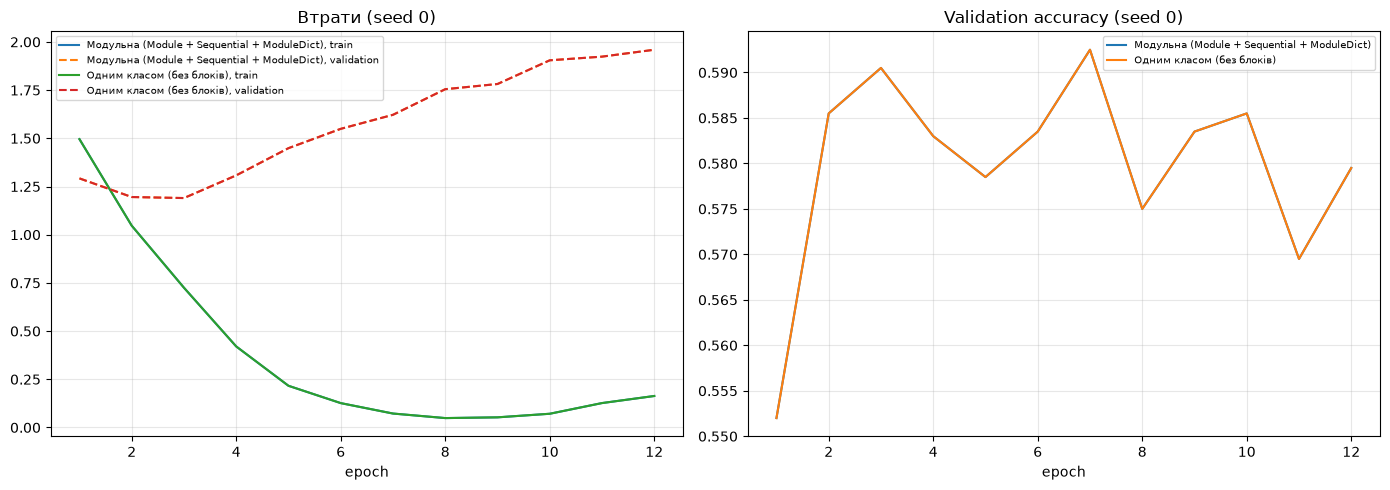

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for (name, seed), history in histories.items():
    if seed != 0:
        continue
    axes[0].plot(range(1, EPOCHS + 1), history['train_loss'], label=f'{name}, train')
    axes[0].plot(range(1, EPOCHS + 1), history['val_loss'], '--', label=f'{name}, validation')
    axes[1].plot(range(1, EPOCHS + 1), history['val_acc'], label=name)
axes[0].set_title('Втрати (seed 0)')
axes[1].set_title('Validation accuracy (seed 0)')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
variants = {
    'relu / tanh (базова)': dict(),
    'lrelu / tanh': dict(enc_activation='lrelu'),
    'relu / relu': dict(dec_activation='relu'),
    'ширші шари [32, 64, 128]': dict(enc_sizes=[32, 64, 128]),
    'додатковий декодерний шар [256, 128, 64]': dict(dec_sizes=[256, 128, 64]),
}

rows = []
for name, kwargs in variants.items():
    enc = kwargs.get('enc_sizes', [16, 32, 64])
    dec = kwargs.get('dec_sizes', [256, 64])
    torch.manual_seed(0)
    net = MyCNNClassifier(3, enc, dec, 10, enc_activation=kwargs.get('enc_activation', 'relu'),
                          dec_activation=kwargs.get('dec_activation', 'tanh'))
    history = train(net, EPOCHS, seed=0)
    test_loss, test_acc = evaluate(net, X_test, y_test)
    rows.append({'варіант': name, 'параметрів': sum(p.numel() for p in net.parameters()),
                 'best val acc': max(history['val_acc']), 'test acc': test_acc,
                 'с / епоху': np.mean(history['epoch_time'])})

variants_table = pd.DataFrame(rows).set_index('варіант')
print(variants_table.round(4).to_string())

                                          параметрів  best val acc  test acc  с / епоху
варіант                                                                                
relu / tanh (базова)                         1090384        0.5925    0.5685     3.4731
lrelu / tanh                                 1090384        0.6045    0.5395     3.5655
relu / relu                                  1090384        0.5985    0.5643     3.4834
ширші шари [32, 64, 128]                     2208848        0.6510    0.6230     5.9140
додатковий декодерний шар [256, 128, 64]     1115344        0.5965    0.5862     3.6504


Зміна архітектури в модульному підході зводиться до зміни аргументів: функція активації передається рядком (через `ModuleDict`), розміри шарів списками, і код класів не чіпається. Ту саму мережу для іншого набору даних можна отримати зміною кількості входів, розміру зображення й кількості класів.

**Результат.** Модульна реалізація і мережа, написана одним класом, дають однаковий результат. Якщо перенести ваги, максимальна різниця виходів дорівнює 0.0. При навчанні з однаковим seed середні показники за трьома запусками збігаються до всіх виведених знаків: best validation accuracy 0.6078, мінімальна validation loss 1.1794 і test accuracy 0.5978 (стандартне відхилення між запусками 0.026). Час епохи також майже однаковий (3.48 с і 3.51 с). Отже, модульний підхід не змінює ні модель, ні якість, ні швидкість, а лише спрощує код.

Додаткові варіанти, що отримуються лише зміною аргументів (один запуск кожного): заміна ReLU на LeakyReLU у згортках дала test accuracy 0.540 проти 0.569 у базової, ReLU у декодері 0.564, а додатковий декодерний шар 0.586. Ширші шари [32, 64, 128] дають найвищу точність (best validation accuracy 0.651, test 0.623), але мають удвічі більше параметрів (2.2 млн проти 1.09 млн) і навчаються повільніше (5.9 с проти 3.5 с на епоху). Різниці між першими варіантами лежать у межах розкиду між запусками (0.026), тому суттєвою можна вважати лише перевагу ширшої мережі.

# Висновки

У цьому практикумі ми навчились будувати моделі в PyTorch за допомогою `Module`, `Sequential`, `ModuleList` і `ModuleDict`: переписувати мережу з блоків, генерувати шари за списком розмірів, розбивати модель на енкодер і декодер та параметризувати функцію активації. Метою завдання було засвоїти способи побудови моделі у PyTorch, і її досягнуто.

**Порівняння з практичною роботою №10.** Мережа з роботи №10 (пакетна нормалізація на вході, три згорткові блоки 16-32-64, max pooling, декодер 256-64 з Tanh і пакетною нормалізацією, 1 090 384 параметри) переписана модульно: блоки `conv_block` і `dec_block` повертають `Sequential`, активація вибирається через `ModuleDict`, енкодер і декодер є окремими модулями, а розмір вектора перед декодером обчислюється автоматично. Така модульна мережа повністю еквівалентна мережі, написаній одним класом: з однаковими вагами виходи збігаються (різниця 0.0), а результати навчання однакові (test accuracy 0.598 для обох). Перевага модульного підходу в коді та гнучкості, а не в точності: щоб змінити активацію, ширину шарів чи кількість шарів, достатньо змінити аргументи, а для іншого набору даних достатньо змінити кількість каналів, розмір зображення та кількість класів.

Абсолютна точність тут (0.598 на тесті) нижча, ніж у роботі №10 (0.748), бо через економію часу тут навчання виконувалось на підвибірці з 10 000 зображень замість 45 000, і навчання тривало менше епох. Тому порівнювати слід не ці числа, а дві реалізації між собою на однакових даних.

**Коли що використовувати.** `Module` для великої моделі, що складається з менших блоків, `Sequential` для невеликого блоку з шарів, `ModuleList` коли потрібно перебирати шари чи зберігати проміжні виходи, `ModuleDict` коли потрібно вибирати за ім'ям частину моделі, наприклад активацію. Під час переписування коду з теорії виправлено кілька помилок: кількість каналів `BatchNorm2d`, розмір вектора перед повнозв'язним шаром, `forward` декодера та невикористаний шар `last`.

# Контрольні питання

**1. Що являє собою блок Module PyTorch?**

`nn.Module` є основним будівельним блоком і базовим класом для всієї нейронної мережі, від нього обов'язково потрібно успадковувати власну модель. У конструкторі `__init__` викликається батьківський конструктор через `super` і створюються шари та підмодулі, а метод `forward` описує, як вхід послідовно проходить через них. Модулі можуть містити інші модулі, що дозволяє вкладати їх у структуру. PyTorch має також функціональні аналоги модулів у `torch.nn.functional`: вони не мають внутрішнього стану, а їхній результат повністю визначається аргументами виклику, наприклад `F.linear` приймає вхід, вагу та зміщення. Module використовують, коли є великий блок, що складається з кількох менших.

**2. Що являє собою ModuleDict, Sequential та ModuleList у PyTorch?**

`Sequential` це контейнер модулів, які складаються разом і виконуються по черзі, тому для нього не потрібно писати `forward`. Його використовують для невеликого блоку з шарів, а список шарів у нього передають через оператор `*`. `ModuleList` зберігає модулі як список, але не має методу `forward`, тому внутрішні шари між собою не з'єднані. Він корисний, коли потрібно перебирати шари й зберігати чи використовувати проміжні виходи, наприклад у U-net. `ModuleDict` зберігає модулі у словнику, і потрібний можна вибирати за ім'ям. Його використовують для параметризації блоків моделі, наприклад функції активації.